# 1. Setup and Imports

Redis Performance Benchmark for CityAirQ
Measures cache performance across all microservices layers.

In [1]:
import requests
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, as_completed

EXTERNAL_IP = "34.46.164.128"
BASE_URL = f"http://{EXTERNAL_IP}:8000"

response = requests.get(f"{BASE_URL}/health")
print(f"Health check: {response.json()}")

Health check: {'status': 'healthy', 'service': 'client_message_handler'}


# 2. Helpers

In [2]:
def test_route_request(payload):
    """Sends a routing request and checks return type and if it's cached."""
    start = time.time()
    try:
        response = requests.post(
            f"{BASE_URL}/route/",
            json=payload,
            timeout=30
        )
        elapsed_ms = (time.time() - start) * 1000
        
        if response.status_code == 200:
            data = response.json()
            cached = data.get("route", {}).get("properties", {}).get("cached", False)
            return {"success": True, "time_ms": elapsed_ms, "cached": cached}
        else:
            return {"success": False, "time_ms": elapsed_ms, "cached": False, "error": response.text}
    except Exception as e:
        return {"success": False, "time_ms": (time.time() - start) * 1000, "cached": False, "error": str(e)}


def test_query_request(payload):
    """Sends a retrieve data request and checks return type and if it's cached.."""
    start = time.time()
    try:
        response = requests.post(
            f"{BASE_URL}/results/",
            json=payload,
            timeout=30
        )
        elapsed_ms = (time.time() - start) * 1000
        
        if response.status_code == 200:
            data = response.json()
            cached = data.get("cached", False)
            return {"success": True, "time_ms": elapsed_ms, "cached": cached}
        else:
            return {"success": False, "time_ms": elapsed_ms, "cached": False, "error": response.text}
    except Exception as e:
        return {"success": False, "time_ms": (time.time() - start) * 1000, "cached": False, "error": str(e)}

# Payloads
ROUTE_PAYLOAD = {
    "start": {"lat": 44.4268, "lon": 26.1025},
    "goal": {"lat": 44.4350, "lon": 26.1100},
    "alpha": 0.5,
    "sensor_types": []
}

QUERY_PAYLOAD = {
    "latitude": 44.4268,
    "longitude": 26.1025,
    "radius": 5.0,
    "layers": ["pm10", "pm25", "no2"]
}

print(f"Route payload: {ROUTE_PAYLOAD}")
print(f"Query payload: {QUERY_PAYLOAD}")

Route payload: {'start': {'lat': 44.4268, 'lon': 26.1025}, 'goal': {'lat': 44.435, 'lon': 26.11}, 'alpha': 0.5, 'sensor_types': []}
Query payload: {'latitude': 44.4268, 'longitude': 26.1025, 'radius': 5.0, 'layers': ['pm10', 'pm25', 'no2']}


# 3. Cache hit vs cache miss (routing request)

In [3]:
print("TEST: Cache Miss vs Cache Hit - Routing")

# Payload for cache miss
import random
unique_route_payload = {
    "start": {"lat": 44.4268 + random.uniform(-0.01, 0.01), "lon": 26.1025},
    "goal": {"lat": 44.4350, "lon": 26.1100},
    "alpha": 0.5,
    "sensor_types": []
}

# First request - Cache MISS
print("\n1. First request (cache miss expected)...")
result1 = test_route_request(unique_route_payload)
print(f"   Time: {result1['time_ms']:.2f} ms")
print(f"   Cached: {result1['cached']}")
print(f"   Success: {result1['success']}")


# Second request - Cache HIT
print("\n2. Second request (cache hit expected)...")
result2 = test_route_request(unique_route_payload)
print(f"   Time: {result2['time_ms']:.2f} ms")
print(f"   Cached: {result2['cached']}")
print(f"   Success: {result2['success']}")


# Calculate speedup
if result1['success'] and result2['success'] and result2['time_ms'] > 0:
    speedup = result1['time_ms'] / result2['time_ms']
    saved_ms = result1['time_ms'] - result2['time_ms']
    print(f"\n--- Results ---")
    print(f"Cache miss: {result1['time_ms']:.2f} ms")
    print(f"Cache hit:  {result2['time_ms']:.2f} ms")
    print(f"Speedup:    {speedup:.2f}x")
    print(f"Time saved: {saved_ms:.2f} ms")

TEST: Cache Miss vs Cache Hit - Routing

1. First request (cache miss expected)...
   Time: 608.39 ms
   Cached: False
   Success: True

2. Second request (cache hit expected)...
   Time: 331.82 ms
   Cached: True
   Success: True

--- Results ---
Cache miss: 608.39 ms
Cache hit:  331.82 ms
Speedup:    1.83x
Time saved: 276.57 ms


# 4. More requests (routing)

In [4]:
print("TEST: Multiple Requests - Statistics")

NUM_REQUESTS = 10

# Unique payloads
unique_payload = {
    "start": {"lat": 44.4268 + random.uniform(-0.01, 0.01), "lon": 26.1025},
    "goal": {"lat": 44.4350 + random.uniform(-0.01, 0.01), "lon": 26.1100},
    "alpha": 0.5,
    "sensor_types": []
}

results = []

print(f"\nSend {NUM_REQUESTS} identical requests...")
for i in range(NUM_REQUESTS):
    result = test_route_request(unique_payload)
    results.append(result)
    status = "HIT" if result['cached'] else "MISS"
    print(f"  Request {i+1:2d}: {result['time_ms']:7.2f} ms [{status}]")

cache_miss_times = [r['time_ms'] for r in results if not r['cached'] and r['success']]
cache_hit_times = [r['time_ms'] for r in results if r['cached'] and r['success']]

print(f"\n--- Statistics ---")
print(f"Cache MISS ({len(cache_miss_times)} requests):")
if cache_miss_times:
    print(f"  Mean: {np.mean(cache_miss_times):.2f} ms")
    print(f"  Std:  {np.std(cache_miss_times):.2f} ms")

print(f"\nCache HIT ({len(cache_hit_times)} requests):")
if cache_hit_times:
    print(f"  Mean: {np.mean(cache_hit_times):.2f} ms")
    print(f"  Std:  {np.std(cache_hit_times):.2f} ms")
    
if cache_miss_times and cache_hit_times:
    avg_speedup = np.mean(cache_miss_times) / np.mean(cache_hit_times)
    print(f"\nAverage speedup: {avg_speedup:.2f}x")

TEST: Multiple Requests - Statistics

Send 10 identical requests...
  Request  1:  495.30 ms [MISS]
  Request  2:  303.46 ms [HIT]
  Request  3:  308.52 ms [HIT]
  Request  4:  336.77 ms [HIT]
  Request  5:  353.25 ms [HIT]
  Request  6:  302.78 ms [HIT]
  Request  7:  307.57 ms [HIT]
  Request  8:  304.86 ms [HIT]
  Request  9:  317.92 ms [HIT]
  Request 10:  380.09 ms [HIT]

--- Statistics ---
Cache MISS (1 requests):
  Mean: 495.30 ms
  Std:  0.00 ms

Cache HIT (9 requests):
  Mean: 323.91 ms
  Std:  25.71 ms

Average speedup: 1.53x


# 5. Graphic (routing)

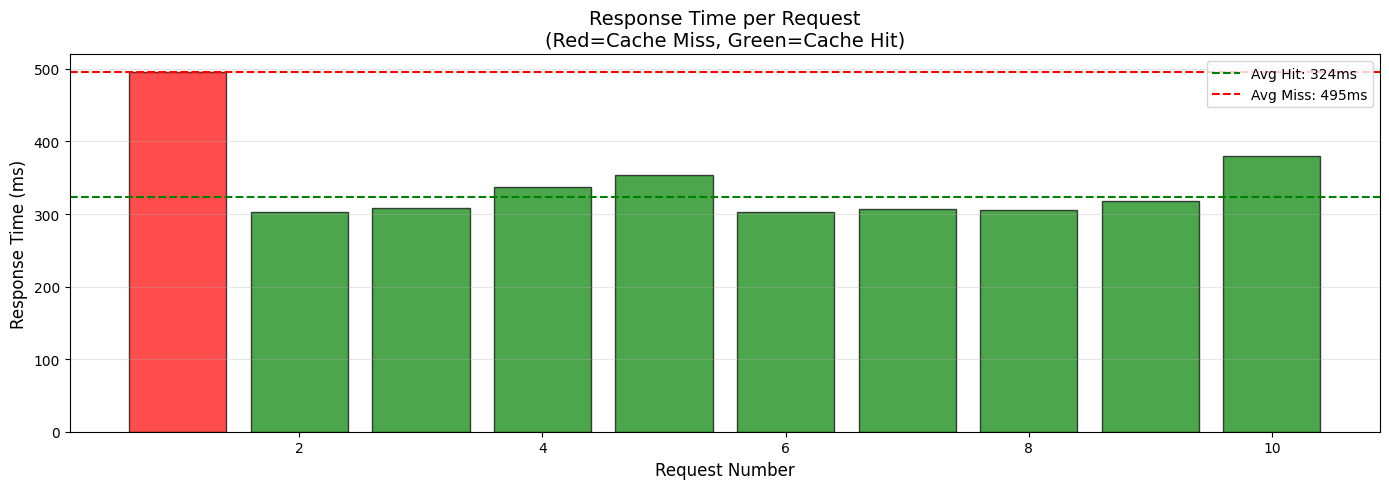

In [18]:
fig, axes = plt.subplots(1, 1, figsize=(14, 5))

# Graphic: Timeline - all requests
ax1 = axes
times = [r['time_ms'] for r in results]
colors = ['red' if not r['cached'] else 'green' for r in results]
bars = ax1.bar(range(1, NUM_REQUESTS + 1), times, color=colors, edgecolor='black', alpha=0.7)

ax1.set_xlabel('Request Number', fontsize=12)
ax1.set_ylabel('Response Time (ms)', fontsize=12)
ax1.set_title('Response Time per Request\n(Red=Cache Miss, Green=Cache Hit)', fontsize=14)
ax1.axhline(y=np.mean(cache_hit_times) if cache_hit_times else 0, 
            color='green', linestyle='--', label=f'Avg Hit: {np.mean(cache_hit_times):.0f}ms')
if cache_miss_times:
    ax1.axhline(y=np.mean(cache_miss_times), 
                color='red', linestyle='--', label=f'Avg Miss: {np.mean(cache_miss_times):.0f}ms')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('images/redis_cache_routing_service.png', dpi=150, bbox_inches='tight')
plt.show()

# 6. Cache hit vs cache miss (query request)

In [ ]:
print("TEST: Cache Miss vs Cache Hit - Query")

# Clear cache first by using unique coordinates
unique_query_payload = {
    "latitude": 44.4268 + random.uniform(-0.005, 0.005),
    "longitude": 26.1025 + random.uniform(-0.005, 0.005),
    "radius": 5.0,
    "layers": ["pm10", "pm25", "no2"]
}

# First request - Cache MISS
print("\n1. First request (cache miss expected)...")
result1_query = test_query_request(unique_query_payload)
print(f"   Time: {result1_query['time_ms']:.2f} ms")
print(f"   Cached: {result1_query['cached']}")
print(f"   Success: {result1_query['success']}")

# Second request - Cache HIT
print("\n2. Second request (cache hit expected)...")
result2_query = test_query_request(unique_query_payload)
print(f"   Time: {result2_query['time_ms']:.2f} ms")
print(f"   Cached: {result2_query['cached']}")
print(f"   Success: {result2_query['success']}")

# Calculate speedup
if result1_query['success'] and result2_query['success'] and result2_query['time_ms'] > 0:
    speedup_query = result1_query['time_ms'] / result2_query['time_ms']
    saved_ms_query = result1_query['time_ms'] - result2_query['time_ms']
    print(f"\n--- Results ---")
    print(f"Cache miss: {result1_query['time_ms']:.2f} ms")
    print(f"Cache hit:  {result2_query['time_ms']:.2f} ms")
    print(f"Speedup:    {speedup_query:.2f}x")
    print(f"Time saved: {saved_ms_query:.2f} ms")

TEST: Cache Miss vs Cache Hit - Query Service

1. First request (cache miss expected)...
   Time: 3744.83 ms
   Cached: False
   Success: True

2. Second request (cache hit expected)...
   Time: 289.18 ms
   Cached: True
   Success: True

--- Results ---
Cache miss: 3744.83 ms
Cache hit:  289.18 ms
Speedup:    12.95x
Time saved: 3455.65 ms


# 7. More requests (query)

In [17]:
print("TEST: Multiple Requests - Statistics")

NUM_REQUESTS_QUERY = 10

# Generate unique payload
unique_query_payload = {
    "latitude": 44.4268 + random.uniform(-0.005, 0.005),
    "longitude": 26.1025 + random.uniform(-0.005, 0.005),
    "radius": 5.0,
    "layers": ["pm10", "pm25", "no2"]
}

query_results = []

print(f"\nSending {NUM_REQUESTS_QUERY} identical requests...")
for i in range(NUM_REQUESTS_QUERY):
    result = test_query_request(unique_query_payload)
    query_results.append(result)
    status = "HIT" if result['cached'] else "MISS"
    print(f"  Request {i+1:2d}: {result['time_ms']:7.2f} ms [{status}]")

# Separate cache miss and cache hit
query_miss_times = [r['time_ms'] for r in query_results if not r['cached'] and r['success']]
query_hit_times = [r['time_ms'] for r in query_results if r['cached'] and r['success']]

print(f"\n--- Statistics ---")
print(f"Cache MISS ({len(query_miss_times)} requests):")
if query_miss_times:
    print(f"  Mean: {np.mean(query_miss_times):.2f} ms")
    print(f"  Std:  {np.std(query_miss_times):.2f} ms")

print(f"\nCache HIT ({len(query_hit_times)} requests):")
if query_hit_times:
    print(f"  Mean: {np.mean(query_hit_times):.2f} ms")
    print(f"  Std:  {np.std(query_hit_times):.2f} ms")
    
if query_miss_times and query_hit_times:
    avg_speedup_query = np.mean(query_miss_times) / np.mean(query_hit_times)
    print(f"\nAverage speedup: {avg_speedup_query:.2f}x")

TEST: Multiple Requests - Statistics

Sending 10 identical requests...
  Request  1: 2723.80 ms [MISS]
  Request  2:  287.50 ms [HIT]
  Request  3:  287.07 ms [HIT]
  Request  4:  289.48 ms [HIT]
  Request  5:  289.70 ms [HIT]
  Request  6:  290.48 ms [HIT]
  Request  7:  289.69 ms [HIT]
  Request  8:  287.97 ms [HIT]
  Request  9:  287.35 ms [HIT]
  Request 10:  292.89 ms [HIT]

--- Statistics ---
Cache MISS (1 requests):
  Mean: 2723.80 ms
  Std:  0.00 ms

Cache HIT (9 requests):
  Mean: 289.13 ms
  Std:  1.77 ms

Average speedup: 9.42x


# 8. Graphic (query)

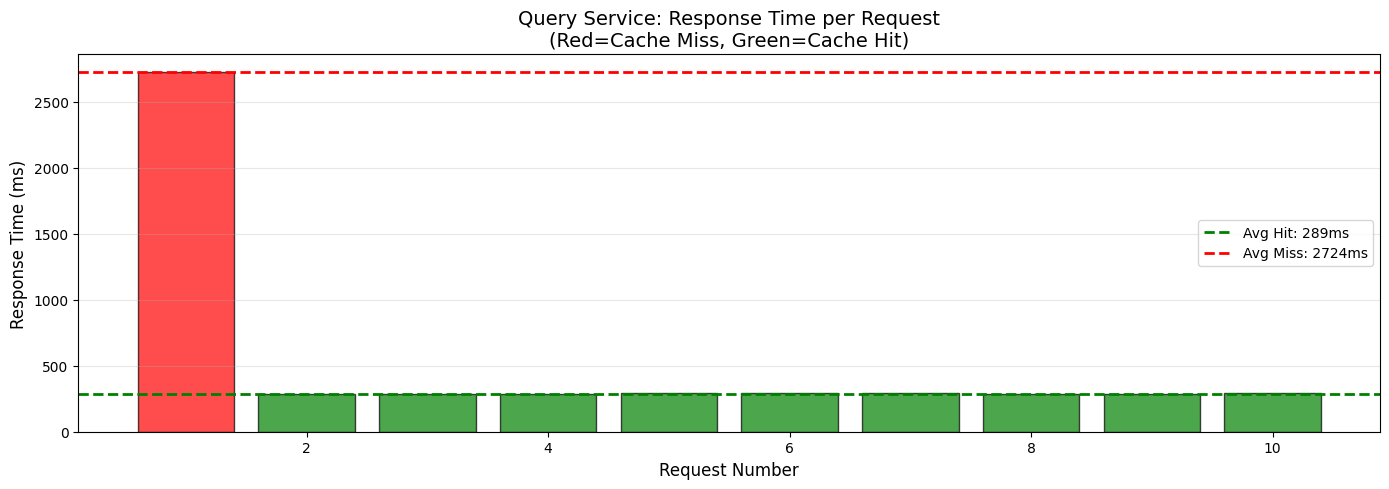

In [21]:
fig, axes = plt.subplots(1, 1, figsize=(14, 5))

# Plot 1: Timeline - all requests
ax1 = axes
query_times = [r['time_ms'] for r in query_results]
query_colors = ['red' if not r['cached'] else 'green' for r in query_results]
bars = ax1.bar(range(1, NUM_REQUESTS_QUERY + 1), query_times, color=query_colors, edgecolor='black', alpha=0.7)

ax1.set_xlabel('Request Number', fontsize=12)
ax1.set_ylabel('Response Time (ms)', fontsize=12)
ax1.set_title('Query Service: Response Time per Request\n(Red=Cache Miss, Green=Cache Hit)', fontsize=14)
ax1.axhline(y=np.mean(query_hit_times) if query_hit_times else 0, 
            color='green', linestyle='--', linewidth=2, label=f'Avg Hit: {np.mean(query_hit_times):.0f}ms')
if query_miss_times:
    ax1.axhline(y=np.mean(query_miss_times), 
                color='red', linestyle='--', linewidth=2, label=f'Avg Miss: {np.mean(query_miss_times):.0f}ms')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('images/redis_cache_query_service.png', dpi=150, bbox_inches='tight')
plt.show()

# 9. Summary


Service              Cache Miss      Cache Hit       Speedup    Time Saved  
------------------------------------------------------------------------
Routing Service          495.30 ms       323.91 ms     1.53x      171.39 ms
Query Service           2723.80 ms       289.13 ms     9.42x     2434.67 ms


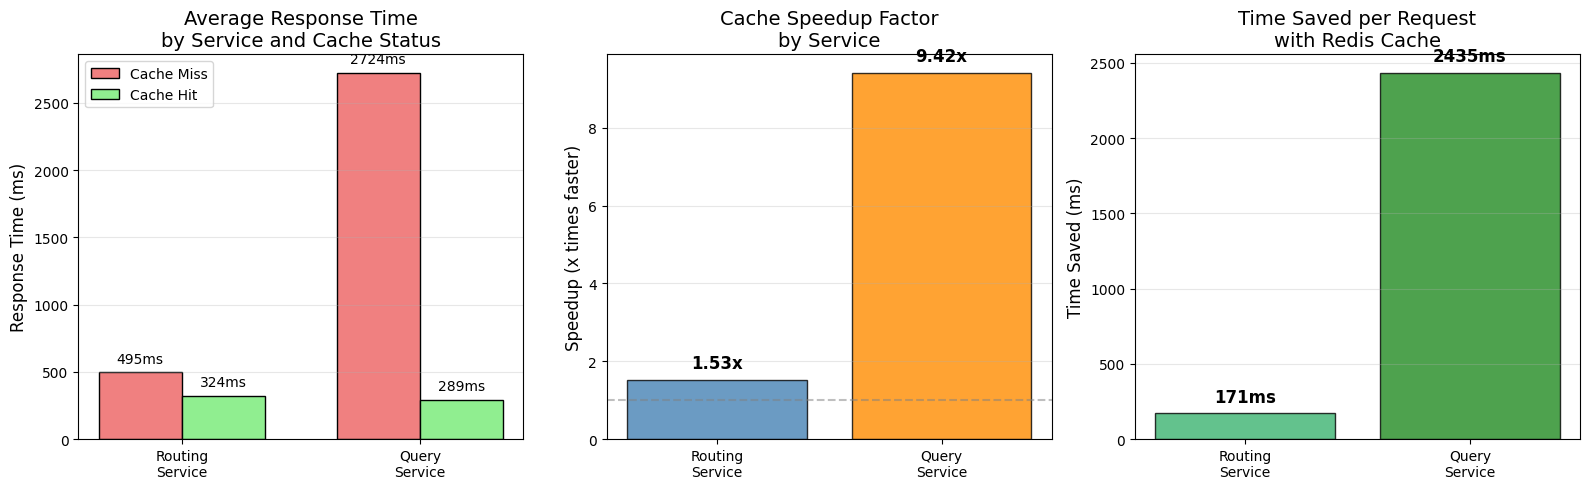

Conclusion

Redis caching provides significant performance improvements:
  - Routing Service: 1.53x faster (171ms saved per request)
  - Query Service:   9.42x faster (2435ms saved per request)

Query Service benefits more from caching due to:
  - Database queries being more expensive than route calculations
  - PubSub message round-trip overhead eliminated on cache hit


In [23]:
# Collect data for summary
routing_miss_avg = np.mean(cache_miss_times) if cache_miss_times else 0
routing_hit_avg = np.mean(cache_hit_times) if cache_hit_times else 0
routing_speedup = routing_miss_avg / routing_hit_avg if routing_hit_avg > 0 else 0

query_miss_avg = np.mean(query_miss_times) if query_miss_times else 0
query_hit_avg = np.mean(query_hit_times) if query_hit_times else 0
query_speedup = query_miss_avg / query_hit_avg if query_hit_avg > 0 else 0

print(f"\n{'Service':<20} {'Cache Miss':<15} {'Cache Hit':<15} {'Speedup':<10} {'Time Saved':<12}")
print("-" * 72)
print(f"{'Routing Service':<20} {routing_miss_avg:>10.2f} ms   {routing_hit_avg:>10.2f} ms   {routing_speedup:>6.2f}x    {routing_miss_avg - routing_hit_avg:>8.2f} ms")
print(f"{'Query Service':<20} {query_miss_avg:>10.2f} ms   {query_hit_avg:>10.2f} ms   {query_speedup:>6.2f}x    {query_miss_avg - query_hit_avg:>8.2f} ms")

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Cache Miss vs Hit comparison (grouped bar)
ax1 = axes[0]
services = ['Routing\nService', 'Query\nService']
miss_times = [routing_miss_avg, query_miss_avg]
hit_times = [routing_hit_avg, query_hit_avg]

x = np.arange(len(services))
width = 0.35

bars1 = ax1.bar(x - width/2, miss_times, width, label='Cache Miss', color='lightcoral', edgecolor='black')
bars2 = ax1.bar(x + width/2, hit_times, width, label='Cache Hit', color='lightgreen', edgecolor='black')

ax1.set_ylabel('Response Time (ms)', fontsize=12)
ax1.set_title('Average Response Time\nby Service and Cache Status', fontsize=14)
ax1.set_xticks(x)
ax1.set_xticklabels(services)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar, val in zip(bars1, miss_times):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             f'{val:.0f}ms', ha='center', va='bottom', fontsize=10)
for bar, val in zip(bars2, hit_times):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             f'{val:.0f}ms', ha='center', va='bottom', fontsize=10)

# Plot 2: Speedup comparison
ax2 = axes[1]
speedups = [routing_speedup, query_speedup]
colors = ['steelblue', 'darkorange']
bars = ax2.bar(services, speedups, color=colors, edgecolor='black', alpha=0.8)

ax2.set_ylabel('Speedup (x times faster)', fontsize=12)
ax2.set_title('Cache Speedup Factor\nby Service', fontsize=14)
ax2.axhline(y=1, color='gray', linestyle='--', alpha=0.5, label='No improvement (1x)')
ax2.grid(axis='y', alpha=0.3)

# Add value labels
for bar, val in zip(bars, speedups):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, 
             f'{val:.2f}x', ha='center', va='bottom', fontsize=12, fontweight='bold')

# Plot 3: Time saved
ax3 = axes[2]
time_saved = [routing_miss_avg - routing_hit_avg, query_miss_avg - query_hit_avg]
bars = ax3.bar(services, time_saved, color=['mediumseagreen', 'forestgreen'], edgecolor='black', alpha=0.8)

ax3.set_ylabel('Time Saved (ms)', fontsize=12)
ax3.set_title('Time Saved per Request\nwith Redis Cache', fontsize=14)
ax3.grid(axis='y', alpha=0.3)

# Add value labels
for bar, val in zip(bars, time_saved):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             f'{val:.0f}ms', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('images/redis_cache_summary.png', dpi=150, bbox_inches='tight')
plt.show()

print("Conclusion")
print(f"\nRedis caching provides significant performance improvements:")
print(f"  - Routing Service: {routing_speedup:.2f}x faster ({routing_miss_avg - routing_hit_avg:.0f}ms saved per request)")
print(f"  - Query Service:   {query_speedup:.2f}x faster ({query_miss_avg - query_hit_avg:.0f}ms saved per request)")
print(f"\nQuery Service benefits more from caching due to:")
print(f"  - Database queries being more expensive than route calculations")
print(f"  - PubSub message round-trip overhead eliminated on cache hit")